Vértices de articulações (vértices de cortes) nas imagens de exemplo

---

Bibliotecas

In [23]:
import cv2

import matplotlib.pyplot as plt
import networkx          as nx
import numpy             as np


---

Carregando a imagem do Josefran

In [24]:
josefran_image = cv2.imread("../../assets/josefran.jpg")
josefran_image = cv2.cvtColor(josefran_image, cv2.COLOR_BGR2GRAY)

josefran_image.shape

(640, 640)

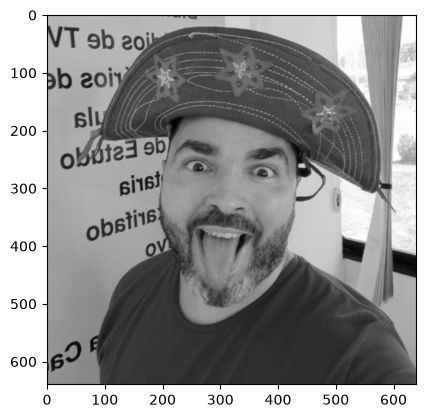

In [25]:
plt.imshow(josefran_image, cmap='gray')
plt.show()

Redimensionando para $64\times64$

In [26]:
josefran_image = cv2.resize(josefran_image, (64, 64), cv2.INTER_LINEAR)
josefran_image.shape

(64, 64)

Visualização da imagem final

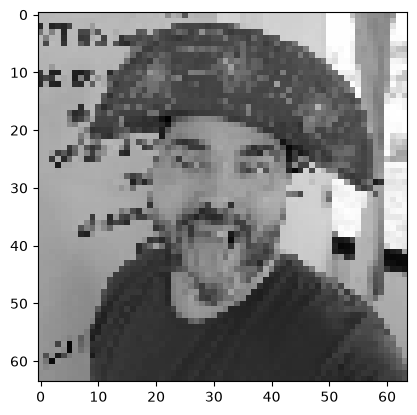

In [27]:
plt.imshow(josefran_image, cmap='gray')
plt.show()

---

Carregando a imagem de um ave

In [28]:
ave_image = cv2.imread("../../assets/ave.jpg")
ave_image = cv2.cvtColor(ave_image, cv2.COLOR_BGR2GRAY)

ave_image.shape

(3874, 4128)

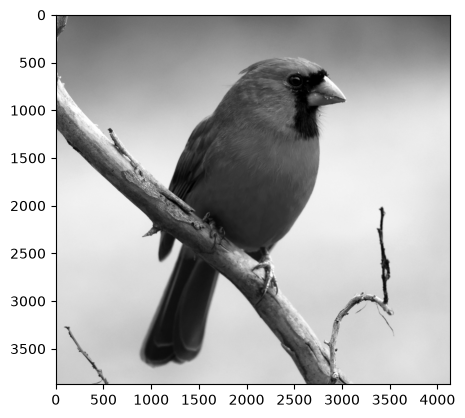

In [29]:
plt.imshow(ave_image, cmap='gray')
plt.show()

Redimensionando para $64\times64$

In [30]:
ave_image = cv2.resize(ave_image, (64, 64), cv2.INTER_LINEAR)
ave_image.shape

(64, 64)

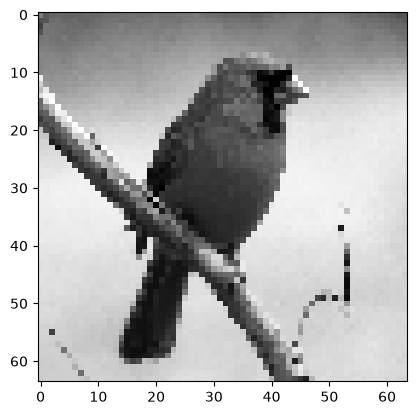

In [31]:
plt.imshow(ave_image, cmap='gray')
plt.show()

Visualização da imagem final

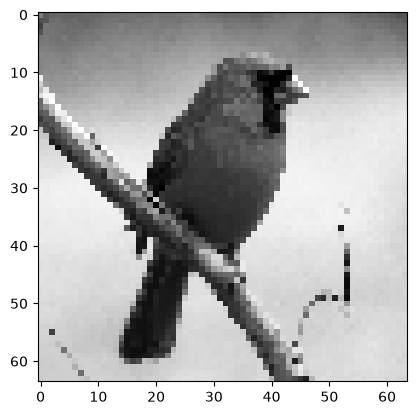

In [32]:
plt.imshow(ave_image, cmap='gray')
plt.show()

---

Carregando a imagem de meme

In [33]:
meme_image = cv2.imread("../../assets/meme.jpg")
meme_image = cv2.cvtColor(meme_image, cv2.COLOR_BGR2GRAY)

meme_image.shape

(598, 598)

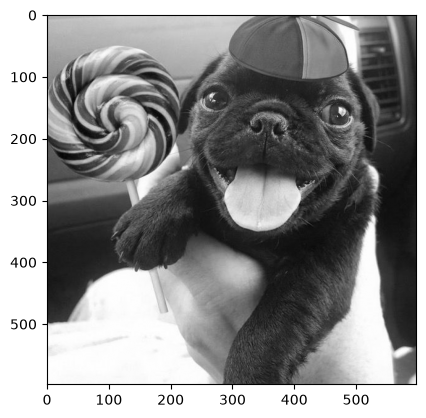

In [34]:
plt.imshow(meme_image, cmap='gray')
plt.show()

Redimensionando para $64\times64$

In [35]:
meme_image = cv2.resize(meme_image, (64, 64), cv2.INTER_LINEAR)
meme_image.shape

(64, 64)

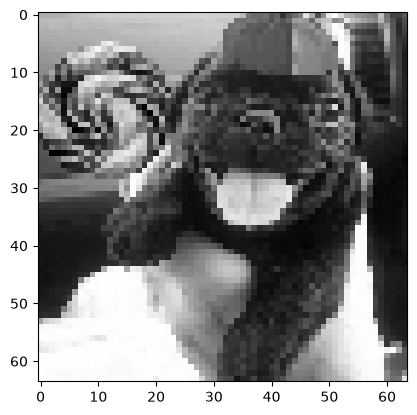

In [36]:
plt.imshow(meme_image, cmap='gray')
plt.show()

Visualização da imagem final

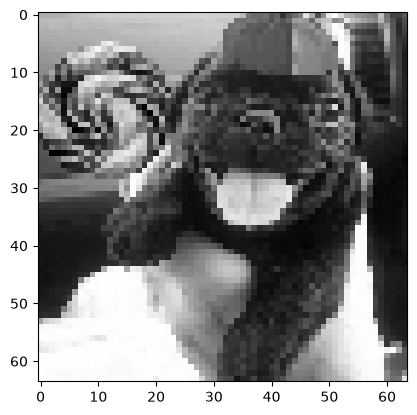

In [37]:
plt.imshow(meme_image, cmap='gray')
plt.show()

---

Algoritmo para construir a representação em grafos de uma imagem

In [38]:
def construir_grafo_imagem(matriz_pixels, vizinhanca=4, limiar=10):
    altura, largura = matriz_pixels.shape
    grafo           = { (i, j): [] for i in range(altura) for j in range(largura) }
    
    # Definir deslocamentos com base na vizinhança
    if vizinhanca == 4:
        direcoes = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    elif vizinhanca == 8:
        direcoes = [(-1, 0), (1, 0), (0, -1), (0, 1), 
                    (-1, -1), (-1, 1), (1, -1), (1, 1)]
    else:
        raise ValueError("A vizinhança deve ser 4 ou 8.")

    for i in range(altura):
        for j in range(largura):
            u = (i, j)
            intensidade_u = matriz_pixels[i, j]
            
            for di, dj in direcoes:
                ni, nj = i + di, j + dj
                
                if 0 <= ni < altura and 0 <= nj < largura:
                    v = (ni, nj)
                    intensidade_v = matriz_pixels[ni, nj]
                    
                    if abs(int(intensidade_u) - int(intensidade_v)) <= limiar:
                        grafo[u].append(v)
                        
    return grafo

---

Algoritmo para encontrar as vértices de articulações

In [39]:
def encontrar_articulacoes(grafo):
    """
    Versão iterativa com DFS e low[] para encontrar vértices de articulação.
    """
    tin = {}
    low = {}
    visitado = set()
    articulacoes = set()
    timer = 0

    for raiz in grafo:
        if raiz in visitado:
            continue

        visitado.add(raiz)
        timer += 1
        tin[raiz] = low[raiz] = timer
        filhos_raiz = 0

        # Cada entrada: [u, pai, iterador_de_vizinhos]
        pilha = [[raiz, None, iter(grafo.get(raiz, []))]]

        while pilha:
            u, pai, vizinhos = pilha[-1]

            try:
                v = next(vizinhos)
                if v == pai:
                    continue

                if v in visitado:
                    if tin[v] < low[u]:
                        low[u] = tin[v]
                else:
                    if pai is None:
                        filhos_raiz += 1

                    visitado.add(v)
                    timer += 1
                    tin[v] = low[v] = timer
                    pilha.append([v, u, iter(grafo.get(v, []))])

            except StopIteration:
                pilha.pop()
                if pilha:
                    p = pilha[-1][0]
                    avo = pilha[-1][1]

                    if low[u] < low[p]:
                        low[p] = low[u]

                    # p não é raiz da árvore DFS e possui filho u com low[u] >= tin[p]
                    if avo is not None and low[u] >= tin[p]:
                        articulacoes.add(p)

        if filhos_raiz >= 2:
            articulacoes.add(raiz)

    return articulacoes

---

Gerando os grafos

In [40]:
josefran_graph_10l  = construir_grafo_imagem(josefran_image, vizinhanca = 4, limiar  = 10)
josefran_graph_100l = construir_grafo_imagem(josefran_image, vizinhanca = 4, limiar = 100)

In [41]:
ave_graph_10l = construir_grafo_imagem(ave_image, vizinhanca = 4, limiar  = 10)
ave_graph_100l = construir_grafo_imagem(ave_image, vizinhanca = 4, limiar = 100)

In [42]:
meme_graph_10l = construir_grafo_imagem(meme_image, vizinhanca = 4, limiar  = 10)
meme_graph_100l = construir_grafo_imagem(meme_image, vizinhanca = 4, limiar = 100)

---

Visualizando os vértices de articulação nos grafos

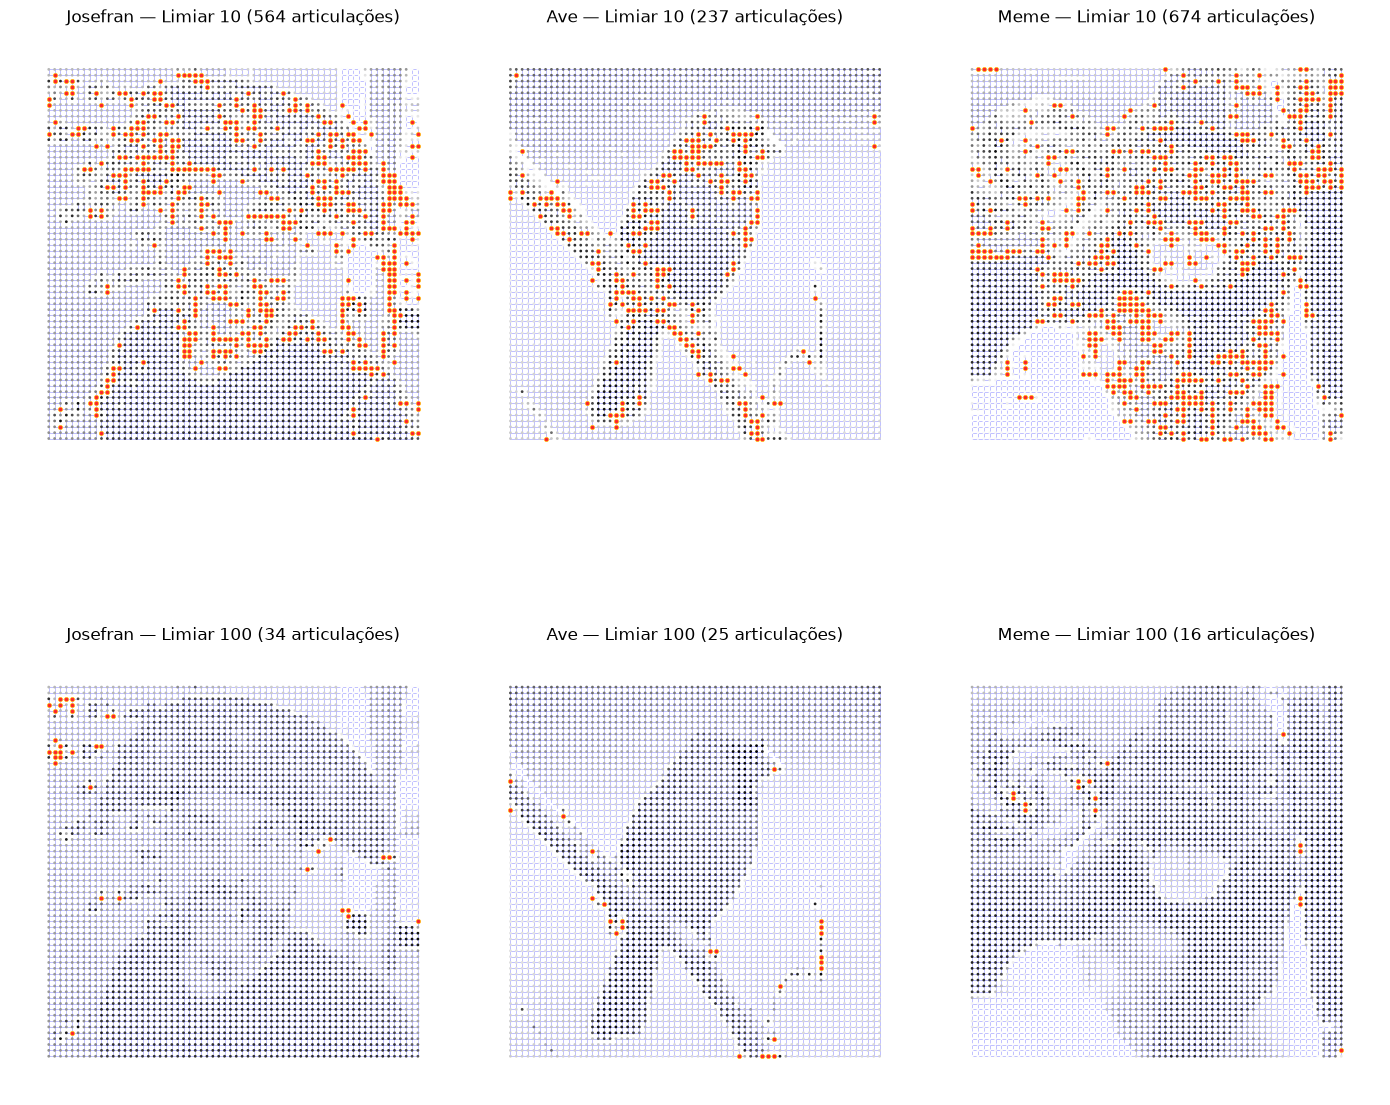

In [43]:
fig, axes = plt.subplots(2, 3, figsize=(14, 14))

configuracoes = [
    (0, 0, josefran_image, josefran_graph_10l,  "Josefran — Limiar 10"),
    (1, 0, josefran_image, josefran_graph_100l, "Josefran — Limiar 100"),

    (0, 1, ave_image,      ave_graph_10l,       "Ave — Limiar 10"),
    (1, 1, ave_image,      ave_graph_100l,      "Ave — Limiar 100"),

    (0, 2, meme_image,     meme_graph_10l,      "Meme — Limiar 10"),
    (1, 2, meme_image,     meme_graph_100l,     "Meme — Limiar 100"),
]

for linha, coluna, matriz_pixels, grafo, titulo in configuracoes:
    ax = axes[linha, coluna]

    # 1. Converter dicionário de adjacência em grafo não direcionado
    G = nx.Graph()
    for u, vizinhos in grafo.items():
        G.add_node(u)
        for v in vizinhos:
            G.add_edge(u, v)

    # 2. Posição espacial alinhada à matriz da imagem (eixo y invertido)
    pos = {u: (u[1], -u[0]) for u in G.nodes()}

    # 3. Separar vértices de articulação e demais nós
    articulacoes = encontrar_articulacoes(grafo)
    nos_articulacao = [u for u in G.nodes() if u in articulacoes]
    nos_normais = [u for u in G.nodes() if u not in articulacoes]

    # 4. Intensidade dos pixels para colorir os nós normais
    cores_normais = [matriz_pixels[u[0], u[1]] for u in nos_normais]

    # 5. Desenhar grafo base e destacar vértices de articulação no subplot correspondente
    nx.draw_networkx_nodes(
        G,
        pos,
        ax=ax,
        nodelist=nos_normais,
        node_size=1,
        node_color=cores_normais,
        cmap=plt.cm.gray,
        vmin=0,
        vmax=255,
    )
    nx.draw_networkx_edges(
        G,
        pos,
        ax=ax,
        width=0.5,
        alpha=0.35,
        edge_color="blue",
    )
    if nos_articulacao:
        nx.draw_networkx_nodes(
            G,
            pos,
            ax=ax,
            nodelist=nos_articulacao,
            node_size=10,
            node_color="#FF1E1E",
            edgecolors="gold",
            linewidths=0.4,
            alpha=0.95,
        )

    ax.set_title(f"{titulo} ({len(nos_articulacao)} articulações)")
    ax.set_aspect("equal")
    ax.axis("off")

plt.tight_layout()
plt.show()